Bounce detected at frame 52 | RGB = (0.715, 0.069, 0.479)
Bounce detected at frame 100 | RGB = (0.044, 0.799, 0.000)
Bounce detected at frame 117 | RGB = (0.044, 0.799, 0.000)

Bounce frames: [52, 100, 117]


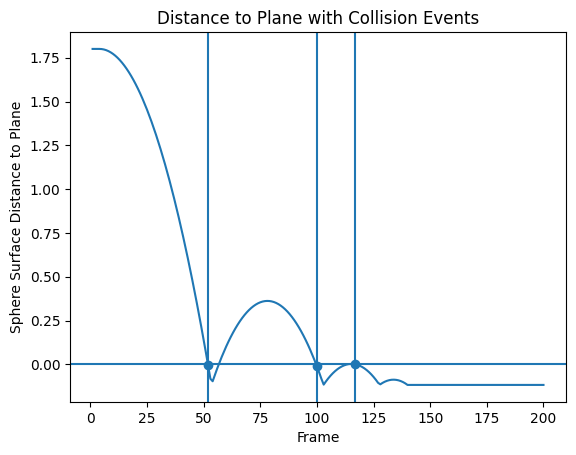

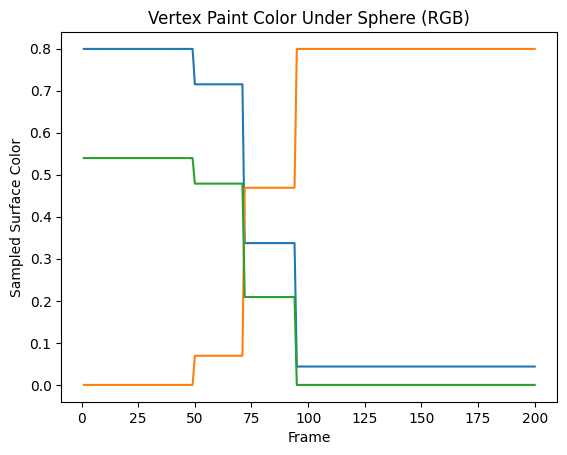

24:22.664  operator         | Saved "bounce.blend"
24:23.632  blend            | Saved session recovery to "/var/folders/0n/w5m51rrn71db4cvkds08wdg80000gn/T/quit.blend"


In [ ]:
import bpy
import bmesh
import matplotlib.pyplot as plt
from mathutils.bvhtree import BVHTree

# --------------------
# CONFIG
# --------------------
BALL_NAME = "Sphere"
PLANE_NAME = "Plane"
COLOR_ATTRIBUTE_NAME = "Col"   # Change if needed
EPSILON = 0.0005

scene = bpy.context.scene
start = scene.frame_start
end = scene.frame_end
depsgraph = bpy.context.evaluated_depsgraph_get()

# --------------------
# Build plane BVH once
# --------------------
plane = bpy.data.objects[PLANE_NAME]
plane_eval = plane.evaluated_get(depsgraph)
plane_mesh = plane_eval.to_mesh()

bm = bmesh.new()
bm.from_mesh(plane_mesh)
bm.transform(plane.matrix_world)
plane_bvh = BVHTree.FromBMesh(bm)
bm.free()

# --------------------
# Access color attribute
# --------------------
color_layer = plane_mesh.color_attributes.get(COLOR_ATTRIBUTE_NAME)

if color_layer is None:
    raise ValueError(f"Color attribute '{COLOR_ATTRIBUTE_NAME}' not found on {PLANE_NAME}")

color_data = color_layer.data

# --------------------
# Scan timeline
# --------------------
ball = bpy.data.objects[BALL_NAME]
original_frame = scene.frame_current

frames = []
distances = []
collision_frames = []
collision_colors = []

colors_r = []
colors_g = []
colors_b = []

was_colliding = False

for frame in range(start, end + 1):
    scene.frame_set(frame)

    center = ball.location
    radius = ball.dimensions.x / 2

    loc, normal, face_index, dist = plane_bvh.find_nearest(center)

    if loc is None:
        continue

    surface_distance = dist - radius

    frames.append(frame)
    distances.append(surface_distance)

    # --------------------
    # Read vertex paint color from closest face
    # --------------------
    poly = plane_mesh.polygons[face_index]

    face_colors = []
    for loop_index in poly.loop_indices:
        c = color_data[loop_index].color
        face_colors.append((c[0], c[1], c[2]))

    if face_colors:
        avg_color = (
            sum(c[0] for c in face_colors) / len(face_colors),
            sum(c[1] for c in face_colors) / len(face_colors),
            sum(c[2] for c in face_colors) / len(face_colors),
        )
    else:
        avg_color = (0.0, 0.0, 0.0)

    colors_r.append(avg_color[0])
    colors_g.append(avg_color[1])
    colors_b.append(avg_color[2])

    # --------------------
    # Bounce detection
    # --------------------
    is_colliding = surface_distance <= EPSILON

    if is_colliding and not was_colliding:
        collision_frames.append(frame)
        collision_colors.append(avg_color)

        print(
            f"Bounce detected at frame {frame} | "
            f"RGB = ({avg_color[0]:.3f}, "
            f"{avg_color[1]:.3f}, "
            f"{avg_color[2]:.3f})"
        )

    was_colliding = is_colliding

scene.frame_set(original_frame)
plane_eval.to_mesh_clear()

print("\nBounce frames:", collision_frames)

# --------------------
# Plot distance
# --------------------
plt.figure()

plt.plot(frames, distances)
plt.axhline(0)

collision_distances = [distances[frames.index(f)] for f in collision_frames]
plt.scatter(collision_frames, collision_distances)

for f in collision_frames:
    plt.axvline(f)

plt.xlabel("Frame")
plt.ylabel("Sphere Surface Distance to Plane")
plt.title("Distance to Plane with Collision Events")

# --------------------
# Plot colors
# --------------------
plt.figure()

plt.plot(frames, colors_r)
plt.plot(frames, colors_g)
plt.plot(frames, colors_b)

plt.xlabel("Frame")
plt.ylabel("Sampled Surface Color")
plt.title("Vertex Paint Color Under Sphere (RGB)")

plt.show()